In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
# Increasing sequences
increasing = np.array([
    [1, 2, 3, 4, 5],
    [2, 3, 4, 5, 6],
    [3, 4, 5, 6, 7],
    [4, 5, 6, 7, 8],
    [5, 6, 7, 8, 9],
    [6, 7, 8, 9, 10],
    [1, 3, 5, 7, 9],
    [2, 4, 6, 8, 10]
])

# Decreasing sequences
decreasing = np.array([
    [5, 4, 3, 2, 1],
    [6, 5, 4, 3, 2],
    [7, 6, 5, 4, 3],
    [8, 7, 6, 5, 4],
    [9, 8, 7, 6, 5],
    [10, 9, 8, 7, 6],
    [9, 7, 5, 3, 1],
    [10, 8, 6, 4, 2]
])

print("Increasing shape:", increasing.shape)
print("Decreasing shape:", decreasing.shape)

Increasing shape: (8, 5)
Decreasing shape: (8, 5)


In [ ]:
X = np.vstack((increasing, decreasing))

y = np.array(
    [0] * len(increasing) +
    [1] * len(decreasing)
)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (16, 5)
y shape: (16,)


In [ ]:
X = X.reshape(16, 5, 1)

print("New X shape:", X.shape)

New X shape: (16, 5, 1)


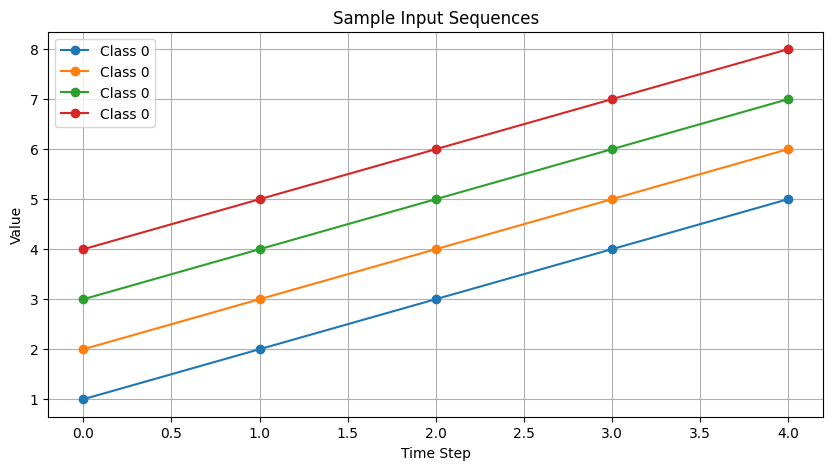

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(4):

    plt.plot(
        X[i, :, 0],
        marker='o',
        label=f"Class {y[i]}"
    )

plt.xlabel("Time Step")
plt.ylabel("Value")
plt.title("Sample Input Sequences")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(5, 1)),
    layers.SimpleRNN(8),
    layers.Dense(1, activation='sigmoid')
])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 8)              │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89 (356.00 B)

 Trainable params: 89 (356.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    X,
    y,
    epochs=100,
    batch_size=4,
    verbose=1
)

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5000 - loss: 1.6861
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5000 - loss: 1.6674
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5000 - loss: 1.6363 
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5000 - loss: 1.6075 
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5000 - loss: 1.5788 
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5000 - loss: 1.5477
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5000 - loss: 1.5186 
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5000 - loss: 1.4814 
Epoch 9/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5000 - loss: 1.4468
Epoch 10/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5000 - loss: 1.4142 
Epoch 11/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5000 - loss: 1.3764
Epoch 12/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5000 - loss

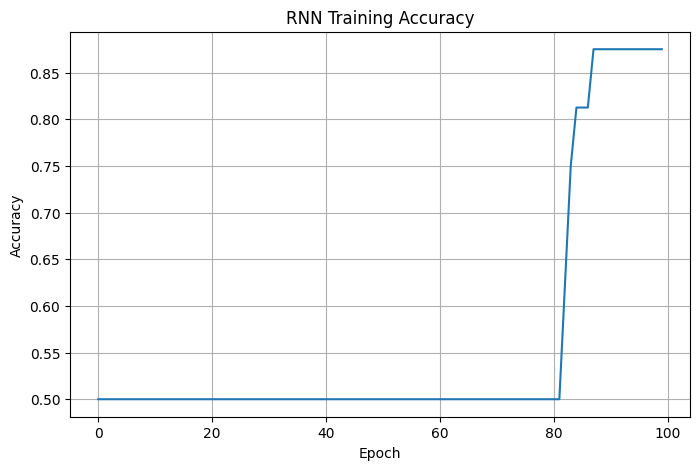

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'])

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN Training Accuracy")
plt.grid(True)

plt.show()

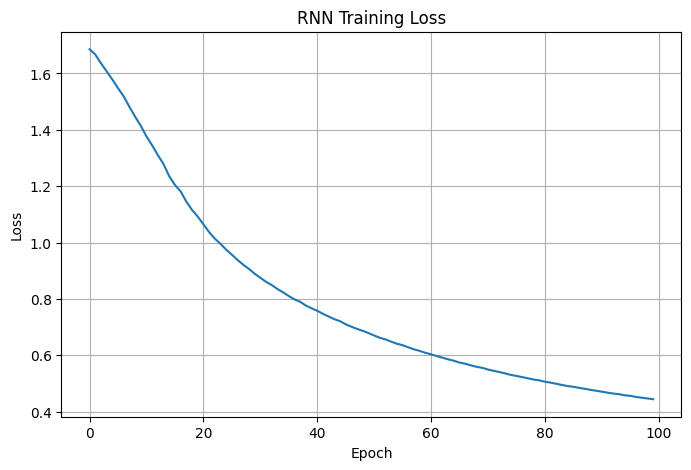

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN Training Loss")
plt.grid(True)

plt.show()

In [ ]:
loss, accuracy = model.evaluate(X, y, verbose=0)

print("Loss:", loss)
print("Accuracy:", accuracy)

Loss: 0.44256502389907837
Accuracy: 0.875


In [ ]:
def predict_sequence(sequence):

    sequence = np.array(sequence)
    sequence = sequence.reshape(1, 5, 1)

    probability = model.predict(sequence, verbose=0)[0][0]

    if probability >= 0.5:
        print("Prediction: DECREASING")
        print("Probability:", probability)
    else:
        print("Prediction: INCREASING")
        print("Probability:", 1 - probability)

In [ ]:
predict_sequence([9, 8, 7, 6, 5])

Prediction: DECREASING
Probability: 0.6383919
